# Sephora Products Analysis: what drives ratings and pricing

**Author:** Chhavi Jain · MSc Data Analytics for Business, Kedge Business School  
**Tools:** Python (pandas, matplotlib, seaborn), SQL (SQLite), Power BI  
**Data:** [Sephora Products and Skincare Reviews](https://www.kaggle.com/datasets/nadyinky/sephora-products-and-skincare-reviews) (Kaggle, file `product_info.csv`)

**Business question:** across Sephora's catalogue, how do price, brand and category relate to customer ratings and review volume, and where are the opportunities for a brand or category manager?

Steps: 1) load and audit data quality, 2) clean with documented decisions, 3) analyse with SQL, 4) visualise, 5) export for the Power BI dashboard.

In [21]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 40, "display.width", 160)
sns.set_theme(style="whitegrid")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "product_info.csv"
OUT = ROOT / "data" / "processed"
IMG = ROOT / "images"
OUT.mkdir(parents=True, exist_ok=True)
IMG.mkdir(parents=True, exist_ok=True)

## 1. Load and audit the data

In [10]:
df = pd.read_csv("product_info.csv")
print(f"{df.shape[0]:,} products x {df.shape[1]} fields")
df.head(3)

8,494 products x 27 fields


,product_id,product_name,brand_id,brand_name,loves_count,rating,reviews,size,variation_type,variation_value,variation_desc,ingredients,price_usd,value_price_usd,sale_price_usd,limited_edition,new,online_only,out_of_stock,sephora_exclusive,highlights,primary_category,secondary_category,tertiary_category,child_count,child_max_price,child_min_price
0,P473671,Fragrance Discovery Set,6342,19-69,6320,3.6364,11.0,NaN,NaN,NaN,NaN,"['Capri Eau de Parfum:', 'Alcohol Denat. (SD A...",35.0,NaN,NaN,0,0,1,0,0,"['Unisex/ Genderless Scent', 'Warm &Spicy Scen...",Fragrance,Value & Gift Sets,Perfume Gift Sets,0,NaN,NaN
1,P473668,La Habana Eau de Parfum,6342,19-69,3827,4.1538,13.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,NaN,"['Alcohol Denat. (SD Alcohol 39C), Parfum (Fra...",195.0,NaN,NaN,0,0,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,85.0,30.0
2,P473662,Rainbow Bar Eau de Parfum,6342,19-69,3253,4.2500,16.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,NaN,"['Alcohol Denat. (SD Alcohol 39C), Parfum (Fra...",195.0,NaN,NaN,0,0,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0


In [11]:
# Data-quality audit
audit = {}
audit["rows"] = len(df)
audit["fields"] = df.shape[1]
audit["duplicate_product_ids"] = int(df["product_id"].duplicated().sum())
audit["no_rating_or_reviews"] = int((df["rating"].isna() | df["reviews"].isna()).sum())
audit["pct_no_rating_or_reviews"] = round(100 * audit["no_rating_or_reviews"] / len(df), 1)

missing_pct = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
audit["sale_price_pct_empty"] = float(missing_pct.get("sale_price_usd", np.nan))
audit["value_price_pct_empty"] = float(missing_pct.get("value_price_usd", np.nan))

# Price outliers with the IQR rule (flagged, not deleted)
q1, q3 = df["price_usd"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
audit["price_outliers_iqr"] = int((df["price_usd"] > upper).sum())
audit["price_outlier_threshold_usd"] = round(float(upper), 2)

print(pd.Series(audit).to_string())
print("\nShare of values missing, top 8 fields:")
print(missing_pct.head(8).to_string())

rows                           8494.0
fields                           27.0
duplicate_product_ids             0.0
no_rating_or_reviews            278.0
pct_no_rating_or_reviews          3.3
sale_price_pct_empty             96.8
value_price_pct_empty            94.7
price_outliers_iqr              845.0
price_outlier_threshold_usd     107.5

Share of values missing, top 8 fields:
sale_price_usd     96.8
value_price_usd    94.7
variation_desc     85.3
child_max_price    67.6
child_min_price    67.6
highlights         26.0
size               19.2
variation_value    18.8


## 2. Cleaning decisions

| Issue | Decision | Why |
|---|---|---|
| Products with no rating or review count | **Keep, leave as missing**, add `has_rating` flag | Zero-filling would fake a "0 stars" product and drag averages down; deleting would remove products from counts |
| `sale_price_usd` / `value_price_usd` almost empty | **Do not impute**; keep a boolean `is_on_sale` | Too sparse to fill; presence of a value is the useful signal |
| Price outliers | **Keep, add `price_outlier` flag** | They are real luxury products, not errors |
| Missing category labels | Label as `Unknown` | Keeps rows in group-by results |
| Price segments | Quartile bands of `price_usd` | Comparable group sizes |

In [12]:
clean = df.copy()
clean["has_rating"] = clean["rating"].notna() & clean["reviews"].notna()
clean["price_outlier"] = clean["price_usd"] > upper
clean["is_on_sale"] = clean["sale_price_usd"].notna()
for c in ["primary_category", "secondary_category", "tertiary_category", "brand_name"]:
    clean[c] = clean[c].fillna("Unknown")
clean["price_band"] = pd.qcut(
    clean["price_usd"], 4, labels=["1 Low", "2 Mid-low", "3 Mid-high", "4 High"], duplicates="drop"
).astype(str)

# 0/1 flags to proper integers
for c in ["limited_edition", "online_only", "out_of_stock", "sephora_exclusive"]:
    if c in clean:
        clean[c] = clean[c].fillna(0).astype(int)

clean.to_csv(OUT / "sephora_products_clean.csv", index=False)
print("Saved cleaned file:", OUT / "sephora_products_clean.csv")

Saved cleaned file: C:\Users\Chhavi Jain\data\processed\sephora_products_clean.csv


## 3. SQL analysis (SQLite)

The cleaned table is loaded into an in-memory SQLite database so every question below is answered with SQL.

In [13]:
con = sqlite3.connect(":memory:")
clean.to_sql("products", con, index=False, if_exists="replace")

overall_rating = pd.read_sql_query("SELECT AVG(rating) AS r FROM products", con)["r"][0]
review_p90 = clean["reviews"].quantile(0.90)
print(f"Catalogue average rating: {overall_rating:.3f} | 90th percentile of review count: {review_p90:.0f}")

Catalogue average rating: 4.195 | 90th percentile of review count: 1097


In [14]:
QUERIES = {}

QUERIES["category_overview"] = """
SELECT primary_category,
       COUNT(*)                      AS products,
       ROUND(AVG(price_usd), 2)      AS avg_price,
       ROUND(AVG(rating), 3)         AS avg_rating,
       SUM(reviews)                  AS total_reviews
FROM products
GROUP BY primary_category
ORDER BY total_reviews DESC;
"""

QUERIES["category_rating_gap"] = """
SELECT primary_category,
       ROUND(AVG(rating), 3) AS avg_rating,
       ROUND(AVG(rating) - (SELECT AVG(rating) FROM products), 3) AS gap_vs_catalogue,
       SUM(reviews) AS total_reviews
FROM products
WHERE has_rating = 1
GROUP BY primary_category
ORDER BY total_reviews DESC;
"""

QUERIES["top_brands_by_review_volume"] = """
SELECT brand_name,
       COUNT(*)                 AS products,
       SUM(reviews)             AS total_reviews,
       ROUND(AVG(rating), 3)    AS avg_rating,
       ROUND(AVG(price_usd), 2) AS avg_price
FROM products
WHERE has_rating = 1
GROUP BY brand_name
HAVING COUNT(*) >= 10
ORDER BY total_reviews DESC
LIMIT 15;
"""

QUERIES["best_rated_brands"] = """
SELECT brand_name, COUNT(*) AS rated_products, ROUND(AVG(rating), 3) AS avg_rating
FROM products
WHERE has_rating = 1
GROUP BY brand_name
HAVING COUNT(*) >= 10
ORDER BY avg_rating DESC
LIMIT 10;
"""

QUERIES["lowest_rated_brands"] = """
SELECT brand_name, COUNT(*) AS rated_products, ROUND(AVG(rating), 3) AS avg_rating
FROM products
WHERE has_rating = 1
GROUP BY brand_name
HAVING COUNT(*) >= 10
ORDER BY avg_rating ASC
LIMIT 10;
"""

QUERIES["price_band_vs_rating"] = """
SELECT price_band,
       COUNT(*)               AS products,
       ROUND(MIN(price_usd), 2) AS min_price,
       ROUND(MAX(price_usd), 2) AS max_price,
       ROUND(AVG(rating), 3)  AS avg_rating,
       ROUND(AVG(reviews), 1) AS avg_reviews
FROM products
WHERE has_rating = 1
GROUP BY price_band
ORDER BY price_band;
"""

QUERIES["sephora_exclusive_effect"] = """
SELECT sephora_exclusive,
       COUNT(*)               AS products,
       ROUND(AVG(rating), 3)  AS avg_rating,
       ROUND(AVG(reviews), 1) AS avg_reviews,
       ROUND(AVG(price_usd), 2) AS avg_price
FROM products
WHERE has_rating = 1
GROUP BY sephora_exclusive;
"""

QUERIES["on_sale_vs_full_price"] = """
SELECT is_on_sale,
       COUNT(*)               AS products,
       ROUND(AVG(rating), 3)  AS avg_rating,
       ROUND(AVG(reviews), 1) AS avg_reviews
FROM products
WHERE has_rating = 1
GROUP BY is_on_sale;
"""

QUERIES["top3_products_per_category"] = """
SELECT primary_category, product_name, brand_name, reviews, rating, price_usd, rank_in_category
FROM (
    SELECT primary_category, product_name, brand_name, reviews, rating, price_usd,
           ROW_NUMBER() OVER (PARTITION BY primary_category ORDER BY reviews DESC) AS rank_in_category
    FROM products
    WHERE has_rating = 1
)
WHERE rank_in_category <= 3
ORDER BY primary_category, rank_in_category;
"""

QUERIES["high_volume_low_rated"] = """
SELECT product_name, brand_name, primary_category, reviews, rating, price_usd
FROM products
WHERE has_rating = 1
  AND reviews >= :review_p90
  AND rating  <  :overall_rating
ORDER BY reviews DESC
LIMIT 25;
"""

res = {}
for name, sql in QUERIES.items():
    res[name] = pd.read_sql_query(sql, con, params={"review_p90": float(review_p90), "overall_rating": float(overall_rating)})
    print(f"--- {name}  ({len(res[name])} rows)")
    print(res[name].head(8).to_string(index=False), "\n")

--- category_overview  (9 rows)
primary_category  products  avg_price  avg_rating  total_reviews
          Makeup      2369      32.76       4.147      1587692.0
        Skincare      2420      60.51       4.229      1090564.0
            Hair      1464      42.79       4.201       359526.0
       Fragrance      1432      87.26       4.231       356485.0
       Mini Size       288      21.40       4.006       197019.0
     Bath & Body       405      42.23       4.195        78602.0
 Tools & Brushes        52      31.92       4.271        11004.0
             Men        60      33.20       4.505         4290.0 

--- category_rating_gap  (9 rows)
primary_category  avg_rating  gap_vs_catalogue  total_reviews
          Makeup       4.147            -0.048      1587692.0
        Skincare       4.229             0.034      1090564.0
            Hair       4.201             0.007       359526.0
       Fragrance       4.231             0.036       356485.0
       Mini Size       4.006         

## 4. Visualisations

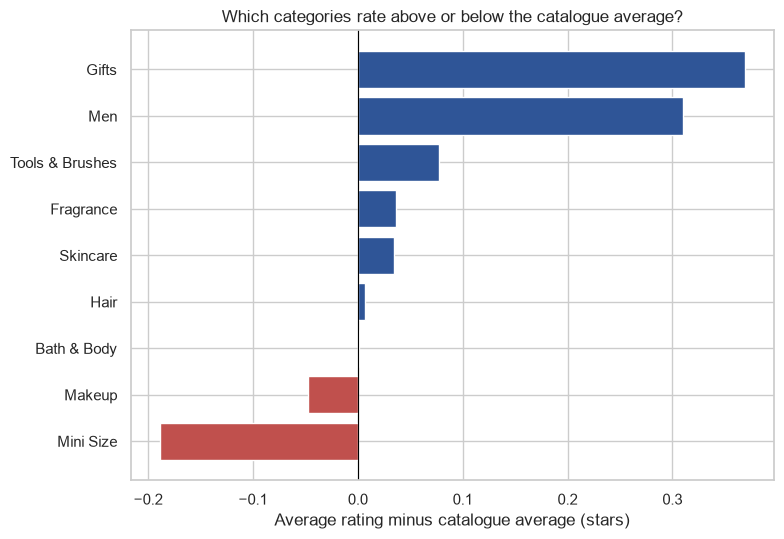

In [15]:
# 1) Rating gap vs the catalogue average, by category
d = res["category_rating_gap"].sort_values("gap_vs_catalogue")
fig, ax = plt.subplots(figsize=(8, 0.45 * len(d) + 1.5))
ax.barh(d["primary_category"], d["gap_vs_catalogue"], color=np.where(d["gap_vs_catalogue"] < 0, "#c0504d", "#2f5597"))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Average rating minus catalogue average (stars)")
ax.set_title("Which categories rate above or below the catalogue average?")
plt.tight_layout(); plt.savefig(IMG / "01_rating_gap_by_category.png", dpi=150); plt.show()

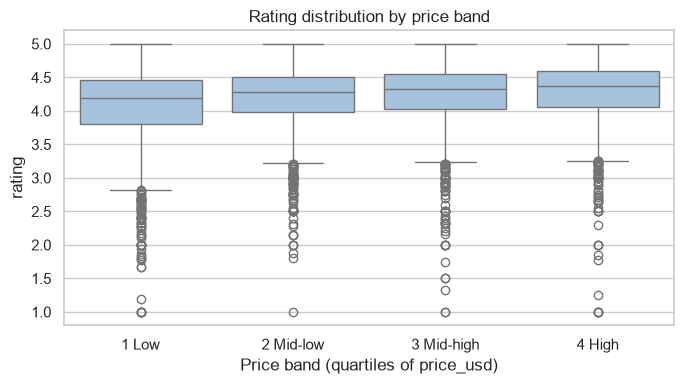

In [16]:
# 2) Price band vs rating
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=clean[clean["has_rating"]], x="price_band", y="rating", order=sorted(clean["price_band"].unique()), color="#9dc3e6", ax=ax)
ax.set_title("Rating distribution by price band"); ax.set_xlabel("Price band (quartiles of price_usd)")
plt.tight_layout(); plt.savefig(IMG / "02_rating_by_price_band.png", dpi=150); plt.show()

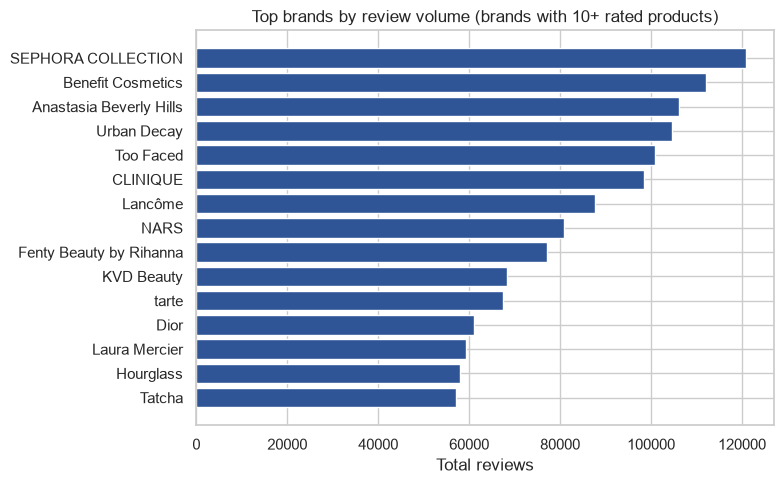

In [17]:
# 3) Top brands by review volume
d = res["top_brands_by_review_volume"].sort_values("total_reviews")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(d["brand_name"], d["total_reviews"], color="#2f5597")
ax.set_xlabel("Total reviews"); ax.set_title("Top brands by review volume (brands with 10+ rated products)")
plt.tight_layout(); plt.savefig(IMG / "03_top_brands_reviews.png", dpi=150); plt.show()

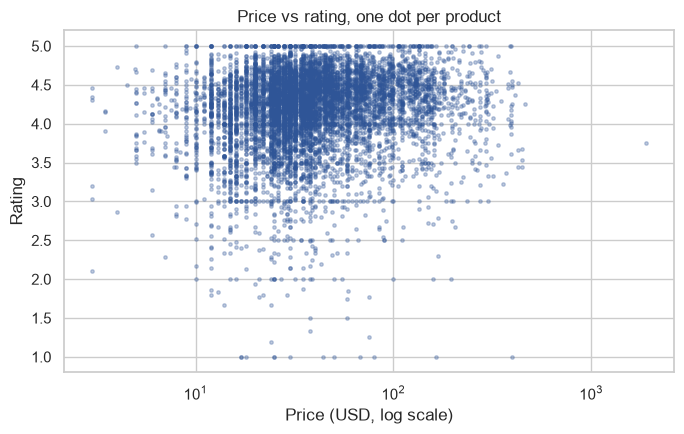

Correlation (Spearman) price vs rating: 0.149


In [18]:
# 4) Price vs rating at product level (log price)
fig, ax = plt.subplots(figsize=(7, 4.5))
r = clean[clean["has_rating"]]
ax.scatter(r["price_usd"], r["rating"], s=6, alpha=0.3, color="#2f5597")
ax.set_xscale("log"); ax.set_xlabel("Price (USD, log scale)"); ax.set_ylabel("Rating")
ax.set_title("Price vs rating, one dot per product")
plt.tight_layout(); plt.savefig(IMG / "04_price_vs_rating.png", dpi=150); plt.show()
print("Correlation (Spearman) price vs rating:", round(r["price_usd"].corr(r["rating"], method="spearman"), 3))

## 5. Key findings

The cell below builds the headline numbers straight from the query results, so nothing is typed by hand. Read the output, then write your own two or three sentences of findings and one recommendation in the README (the numbers will differ from any example you have seen).

In [19]:
cat = res["category_rating_gap"]
top = cat.iloc[0]
low = cat.sort_values("gap_vs_catalogue").iloc[0]
pb = res["price_band_vs_rating"]
corr = r["price_usd"].corr(r["rating"], method="spearman")

print(f"1) Highest review volume: '{top['primary_category']}' with {int(top['total_reviews']):,} reviews; "
      f"its average rating is {top['gap_vs_catalogue']:+.2f} stars vs the catalogue average ({overall_rating:.2f}).")
print(f"2) Weakest category by rating: '{low['primary_category']}' ({low['gap_vs_catalogue']:+.2f} stars vs catalogue).")
print(f"3) Rating by price band: " + ", ".join(f"{b} = {v:.2f}" for b, v in zip(pb['price_band'], pb['avg_rating'])))
print(f"4) Spearman correlation between price and rating: {corr:.2f}")
print(f"5) {len(res['high_volume_low_rated'])} high-volume (top 10% by reviews) products rate below the catalogue average, listed in 'high_volume_low_rated'.")

1) Highest review volume: 'Makeup' with 1,587,692 reviews; its average rating is -0.05 stars vs the catalogue average (4.19).
2) Weakest category by rating: 'Mini Size' (-0.19 stars vs catalogue).
3) Rating by price band: 1 Low = 4.09, 2 Mid-low = 4.20, 3 Mid-high = 4.24, 4 High = 4.27
4) Spearman correlation between price and rating: 0.15
5) 25 high-volume (top 10% by reviews) products rate below the catalogue average, listed in 'high_volume_low_rated'.


## 6. Export for Power BI

In [20]:
res["category_rating_gap"].to_csv(OUT / "pbi_category.csv", index=False)
res["top_brands_by_review_volume"].to_csv(OUT / "pbi_top_brands.csv", index=False)
res["price_band_vs_rating"].to_csv(OUT / "pbi_price_band.csv", index=False)
res["high_volume_low_rated"].to_csv(OUT / "pbi_high_volume_low_rated.csv", index=False)
print("Power BI input: data/processed/sephora_products_clean.csv (main table) + the pbi_*.csv summaries")

# Numbers to quote in the README and on the CV (copied from this run)
cv = {
    "products": audit["rows"], "fields": audit["fields"],
    "no_rating_or_reviews": audit["no_rating_or_reviews"], "pct_no_rating": audit["pct_no_rating_or_reviews"],
    "price_outliers": audit["price_outliers_iqr"],
    "sale_price_pct_empty": audit["sale_price_pct_empty"], "value_price_pct_empty": audit["value_price_pct_empty"],
    "sql_queries": len(QUERIES), "brands": clean["brand_name"].nunique(),
    "categories": clean["primary_category"].nunique(),
}
print("\nCV NUMBERS:", cv)
Path(OUT / "sql_all_queries.sql").write_text("\n".join(f"-- {k}\n{v.strip()}\n" for k, v in QUERIES.items()))

Power BI input: data/processed/sephora_products_clean.csv (main table) + the pbi_*.csv summaries

CV NUMBERS: {'products': 8494, 'fields': 27, 'no_rating_or_reviews': 278, 'pct_no_rating': 3.3, 'price_outliers': 845, 'sale_price_pct_empty': 96.8, 'value_price_pct_empty': 94.7, 'sql_queries': 10, 'brands': 304, 'categories': 9}


2964